In [2]:
from ultralytics import YOLO

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import numpy as np
import json

In [7]:
model_26m = YOLO('yolo26m.pt')

In [15]:
metrics = model_26m.val(
    data='../data/validation/coco.yaml', 
    conf=0.25,
    save=False,
    device='cpu', 
    verbose=False,
    plots=True
)

Ultralytics 8.4.176  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450H)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 464.4±273.0 MB/s, size: 121.1 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 313/313 9.8s/it 51:004.2ss4
                   all       5000      36335      0.729      0.644      0.607      0.466
Speed: 1.4ms preprocess, 596.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\detect\val-2


In [16]:
np.save("../outputs/cm_coco.npy", metrics.confusion_matrix.matrix)
np.save("../outputs/ap_por_clase.npy", metrics.box.maps)
with open("../outputs/metricas_coco.json", "w") as f:
    json.dump(metrics.results_dict, f, indent=2)

In [17]:
print("mAP50-95:", metrics.box.map, "| mAP50:", metrics.box.map50)
print("AP del gato:", metrics.box.maps[15])

mAP50-95: 0.46562574096461723 | mAP50: 0.6069272007672575
AP del gato: 0.7596326553211041


In [18]:
cm = np.load("../outputs/cm_coco.npy")
maps = np.load("../outputs/ap_por_clase.npy")
with open("../outputs/metricas_coco.json") as f:
    res = json.load(f)

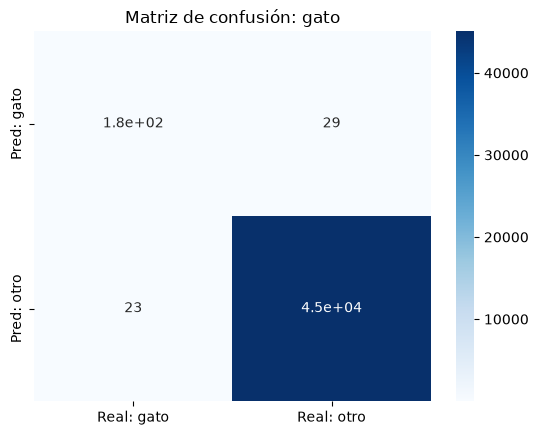

Precisión: 0.861 | Recall: 0.886


In [23]:
c = 15                                           # cat
bg = cm.shape[0] - 1                             # última fila/columna = fondo

TP = cm[c, c]
FP = cm[c, :].sum() - TP    # predijo gato y no lo era
FN = cm[:, c].sum() - TP    # era gato y no lo detectó
TN = cm.sum() - TP - FP - FN

cm_cat = np.array([[TP, FP],
                   [FN, TN]])   # TN no se muestra: no aporta para gatos

sns.heatmap(cm_cat, annot=True, cmap='Blues',
            xticklabels=['Real: gato', 'Real: otro'],
            yticklabels=['Pred: gato', 'Pred: otro'])
plt.title('Matriz de confusión: gato')
plt.show()

print(f"Precisión: {TP/(TP+FP):.3f} | Recall: {TP/(TP+FN):.3f}")

In [21]:
from pathlib import Path

carpeta = Path(r"C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\val2017")   # la que tiene los .jpg y los .txt de COCO

print("Existe:", carpeta.exists())
txts = list(carpeta.glob("*.txt"))
print("Archivos .txt:", len(txts))

if txts:
    print("Ejemplo:", txts[0].name)
    print(txts[0].read_text()[:200])

n = 0
for t in txts:
    for l in t.read_text().splitlines():
        if l.split() and l.split()[0] == "15":
            n += 1
print("Gatos en las etiquetas:", n)

Existe: True
Archivos .txt: 4952
Ejemplo: 000000000139.txt
58 0.389578 0.416103 0.0385937 0.163146
62 0.127641 0.505153 0.233312 0.2227
62 0.934195 0.583462 0.127109 0.184812
56 0.604656 0.632547 0.0875 0.241385
56 0.502508 0.627324 0.0966094 0.231174
56 0.66
Gatos en las etiquetas: 202


In [22]:
import json
with open(r"C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\annotations\instances_val2017.json", encoding="utf-8") as f:
    d = json.load(f)
n = sum(1 for a in d["annotations"] if a["category_id"] == 17 and not a.get("iscrowd", 0))
print("Gatos en el JSON:", n)

Gatos en el JSON: 202
